Dataset:
  Purchase_ID Customer_ID  Age  Gender    City       Product     Category  \
0        P001        C101   22  Female    Pune    Headphones  Electronics   
1        P002        C102   30    Male  Mumbai      Notebook   Stationery   
2        P003        C103   25  Female    Pune      Backpack      Fashion   
3        P004        C101   22  Female    Pune     USB Cable  Electronics   
4        P005        C104   41    Male  Nashik  Water Bottle         Home   

   Unit_Price_INR  Quantity  Total_Amount_INR Payment_Method  
0            1200         1              1200            UPI  
1              80         3               240           Cash  
2             900         1               900    Credit Card  
3             250         2               500            UPI  
4             350         2               700     Debit Card  

Decision Tree Accuracy: 25.0 %

Classification Report:
              precision    recall  f1-score   support

 Electronics       0.50      1.00      

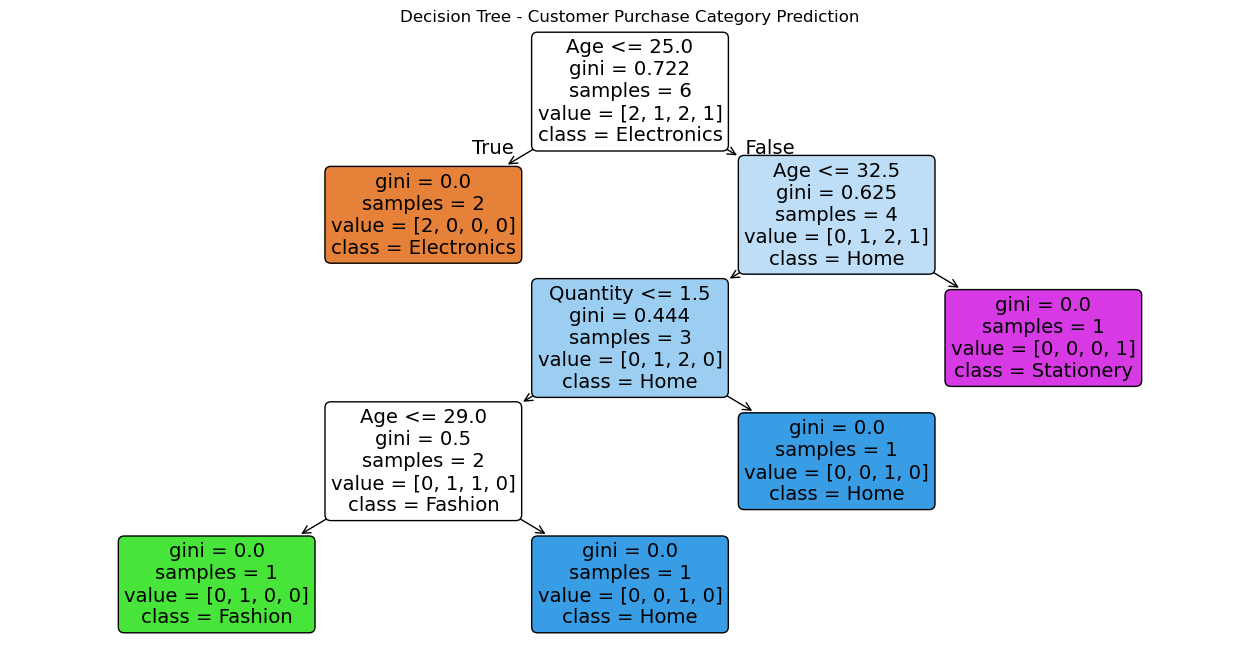

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv("small_customer_purchase_dataset.csv")

print("Dataset:")
print(df.head())

# Encode categorical columns
df["Gender"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

# Remove rows with missing values in selected columns
df = df.dropna(subset=["Gender", "Age", "Unit_Price_INR",
                       "Quantity", "Category"])

# Select features and target
X = df[["Age", "Gender", "Unit_Price_INR", "Quantity"]]
y = df["Category"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)


# Create and train model
model = DecisionTreeClassifier(
    criterion="gini", random_state=42, max_depth=4
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)
print("\nDecision Tree Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Visualize decision tree
plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)
plt.title("Decision Tree - Customer Purchase Category Prediction")
plt.show()


Dataset:
  Purchase_ID Customer_ID  Age  Gender    City       Product     Category  \
0        P001        C101   22  Female    Pune    Headphones  Electronics   
1        P002        C102   30    Male  Mumbai      Notebook   Stationery   
2        P003        C103   25  Female    Pune      Backpack      Fashion   
3        P004        C101   22  Female    Pune     USB Cable  Electronics   
4        P005        C104   41    Male  Nashik  Water Bottle         Home   

   Unit_Price_INR  Quantity  Total_Amount_INR Payment_Method  
0            1200         1              1200            UPI  
1              80         3               240           Cash  
2             900         1               900    Credit Card  
3             250         2               500            UPI  
4             350         2               700     Debit Card  


ValueError: The test_size = 2 should be greater or equal to the number of classes = 4